# Figure 2 Supplemental
Stochastic molecular model implementation

Load libraries

Add paths to PySB models in Python folder

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.insert(0, "../../Python/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, "../../Python/fit")

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from cell_cycle_death_model import model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    


In [3]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd() + '/../../Python/model_data/parameters.csv')
# del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [4]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/../../Python/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [10]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)
size = (3.5, 2.5)


In [6]:
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.6
model.parameters['AKT'].value = 0.6

In [7]:
%%time

### Stochastic simulation

t_ssa = np.linspace(0, 120, 120001);
sim = BngSimulator(model, tspan=t_ssa, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout_div = simres.observables;


CPU times: total: 2.64 s
Wall time: 7.73 s


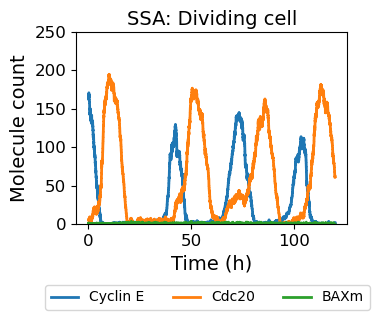

In [19]:
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsBAXm']; #plot Cyclin E, Cdc20 and Cyclin A
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t_ssa,yout_div[observables[obs]], label=label[obs], lw=2)

plt.xlabel('Time (h)')
plt.ylabel('Molecule count')
plt.title('SSA: Dividing cell')
plt.ylim(0, 250)

fig.legend(label, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.26))
# ax = plt.gca()
# ax.tick_params(labelbottom=False)
# ax.tick_params(labelleft=False)

fig2_supp_fn = Path(SAVEDIR, 'fig2_supp.svg')
if SAVEFILES and (OVERWRITE or not fig2_supp_fn.exists()):
    plt.savefig(fig2_supp_fn, bbox_inches='tight')
else:
    plt.figure()